In [1]:
# IMPORT LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')
%matplotlib inline
pd.set_option('display.float_format', lambda x: '%.3f' % x)
plt.rcParams["figure.figsize"] = (10,6)

In [2]:
import pandas as pd
from pathlib import Path

# Official NSL-KDD dataset files
train_path = Path("datasets/nsl-kdd/KDDTrain+.txt")
test_path = Path("datasets/nsl-kdd/KDDTest+.txt")

# NSL-KDD contains 41 features followed by the attack label and difficulty level
columns = [
    "duration", "protocol_type", "service", "flag", "src_bytes",
    "dst_bytes", "land", "wrong_fragment", "urgent", "hot",
    "num_failed_logins", "logged_in", "num_compromised",
    "root_shell", "su_attempted", "num_root", "num_file_creations",
    "num_shells", "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count", "srv_count",
    "serror_rate", "srv_serror_rate", "rerror_rate",
    "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
    "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate",
    "label", "difficulty"
]

train_df = pd.read_csv(
    train_path, names=columns, header=None
)

test_df = pd.read_csv(
    test_path, names=columns, header=None
)

print("Training set shape:", train_df.shape)
print("Test set shape:", test_df.shape)

print("\nTraining labels:")
print(train_df["label"].value_counts().head())

print("\nTest labels:")
print(test_df["label"].value_counts().head())

Training set shape: (125973, 43)
Test set shape: (22544, 43)

Training labels:
label
normal       67343
neptune      41214
satan         3633
ipsweep       3599
portsweep     2931
Name: count, dtype: int64

Test labels:
label
normal          9711
neptune         4657
guess_passwd    1231
mscan            996
warezmaster      944
Name: count, dtype: int64


In [3]:
#Step 2 — Create binary labels: Normal vs Attack

In [4]:
# Create binary labels while preserving the official train/test split
train_df["binary_label"] = (train_df["label"] != "normal").astype(int)
test_df["binary_label"] = (test_df["label"] != "normal").astype(int)

print("Training binary label distribution:")
print(train_df["binary_label"].value_counts().sort_index())

print("\nTest binary label distribution:")
print(test_df["binary_label"].value_counts().sort_index())

print("\nTraining class proportions:")
print(train_df["binary_label"].value_counts(normalize=True).sort_index().round(4))

print("\nTest class proportions:")
print(test_df["binary_label"].value_counts(normalize=True).sort_index().round(4))

Training binary label distribution:
binary_label
0    67343
1    58630
Name: count, dtype: int64

Test binary label distribution:
binary_label
0     9711
1    12833
Name: count, dtype: int64

Training class proportions:
binary_label
0   0.535
1   0.465
Name: proportion, dtype: float64

Test class proportions:
binary_label
0   0.431
1   0.569
Name: proportion, dtype: float64


In [5]:
#Dataset	Normal (0)	Attack (1)
#Training	53.5%	46.5%
#Test	43.1%	56.9%

#The test set contains a larger proportion of attacks than the training set. This is an important characteristic 
#to mention when interpreting your results: performance on the official test set may differ from performance on the training data.

In [6]:
#Step 3 — Separate features and target

In [7]:
# Separate features (X) and binary targets (y)
feature_columns = [
    col for col in columns
    if col not in ["label", "difficulty"]
]

X_train = train_df[feature_columns].copy()
y_train = train_df["binary_label"].copy()

X_test = test_df[feature_columns].copy()
y_test = test_df["binary_label"].copy()

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nCategorical features:")
print(X_train.select_dtypes(include=["object"]).columns.tolist())

print("\nMissing values in training features:", X_train.isnull().sum().sum())
print("Missing values in test features:", X_test.isnull().sum().sum())

X_train shape: (125973, 41)
y_train shape: (125973,)
X_test shape: (22544, 41)
y_test shape: (22544,)

Categorical features:
['protocol_type', 'service', 'flag']

Missing values in training features: 0
Missing values in test features: 0


In [8]:
#Step 4 — Preprocess the features

In [9]:
#Build and fit the preprocessing pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numerical and categorical features
categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    exclude=["object"]
).columns.tolist()

# Preprocessing for categorical and numerical features
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the learned transformations to the test data
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed test shape:", X_test_processed.shape)
print("Number of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))


Processed training shape: (125973, 122)
Processed test shape: (22544, 122)
Number of numerical features: 38
Number of categorical features: 3


In [10]:
# Train the models

In [11]:
#Train all three models and measure training time

import time
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Define the three classifiers
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "SVM (RBF)": SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

binary_results = []
binary_probabilities = {}
training_times = {}

for name, model in models.items():

    print(f"Training {name}...")

    # Measure training time only
    start_time = time.perf_counter()

    model.fit(X_train_processed, y_train)

    end_time = time.perf_counter()
    training_times[name] = end_time - start_time

    print(f"Training completed in {training_times[name]:.2f} seconds")

    # Predict attack probabilities on the official test set
    probabilities = model.predict_proba(X_test_processed)[:, 1]
    binary_probabilities[name] = probabilities

    # Baseline threshold = 0.5
    predictions = (probabilities >= 0.5).astype(int)

    binary_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1-score": f1_score(y_test, predictions),
        "Training Time (s)": training_times[name]
    })

binary_results_df = pd.DataFrame(binary_results).set_index("Model")

print("\nBinary classification results (threshold = 0.5):")
display(binary_results_df.round(4))

Training Logistic Regression...
Training completed in 18.91 seconds
Training SVM (RBF)...
Training completed in 926.10 seconds
Training Random Forest...
Training completed in 16.50 seconds

Binary classification results (threshold = 0.5):


,Accuracy,Precision,Recall,F1-score,Training Time (s)
Model,,,,,
Logistic Regression,0.754,0.917,0.624,0.742,18.912
SVM (RBF),0.766,0.963,0.613,0.749,926.097
Random Forest,0.767,0.967,0.611,0.749,16.504


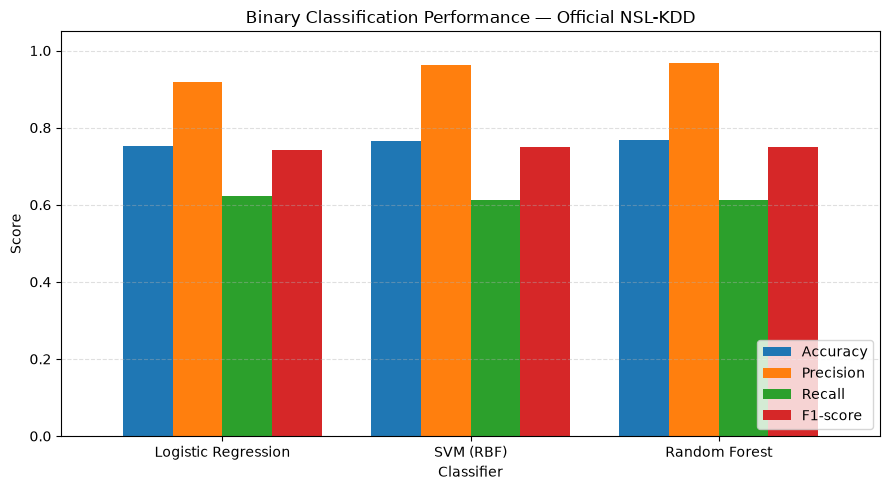

In [12]:
#Bar chart for classification metrics
import matplotlib.pyplot as plt

# Classification metrics comparison
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

ax = binary_results_df[metrics].plot(
    kind="bar",
    figsize=(9, 5),
    width=0.8
)

ax.set_title("Binary Classification Performance — Official NSL-KDD")
ax.set_xlabel("Classifier")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.legend(loc="lower right")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

plt.tight_layout()

# Save at high resolution for the IEEE report
plt.savefig(
    "nsl_kdd_binary_metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

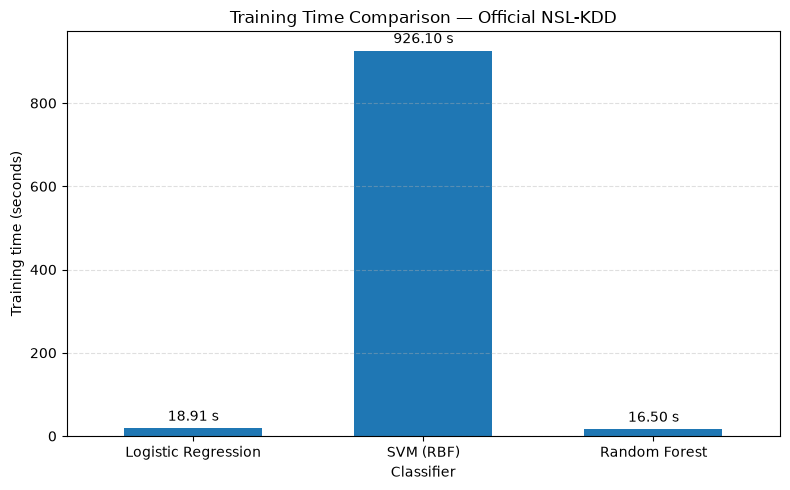

In [13]:
#Bar chart for training time
training_time_series = binary_results_df["Training Time (s)"]

ax = training_time_series.plot(
    kind="bar",
    figsize=(8, 5),
    width=0.6
)

ax.set_title("Training Time Comparison — Official NSL-KDD")
ax.set_xlabel("Classifier")
ax.set_ylabel("Training time (seconds)")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

# Display the exact training time above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f s", padding=3)

plt.tight_layout()

plt.savefig(
    "nsl_kdd_binary_training_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
# Evaluate multiple classification thresholds

In [15]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

thresholds_to_test = [
    0.1, 0.2, 0.3, 0.4, 0.5,
    0.6, 0.7, 0.8, 0.9
]

threshold_results = []

for model_name, probabilities in binary_probabilities.items():
    for threshold in thresholds_to_test:

        predictions = (probabilities >= threshold).astype(int)

        threshold_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "F1-score": f1_score(
                y_test, predictions, zero_division=0
            )
        })

threshold_results_df = pd.DataFrame(threshold_results)

display(
    threshold_results_df.round(4)
)

,Model,Threshold,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.100,0.784,0.902,0.697,0.786
1,Logistic Regression,0.200,0.773,0.909,0.668,0.770
2,Logistic Regression,0.300,0.762,0.913,0.644,0.755
3,Logistic Regression,0.400,0.757,0.915,0.632,0.748
4,Logistic Regression,0.500,0.754,0.917,0.624,0.742
5,Logistic Regression,0.600,0.749,0.918,0.614,0.736
6,Logistic Regression,0.700,0.743,0.918,0.602,0.728
7,Logistic Regression,0.800,0.736,0.918,0.589,0.718
8,Logistic Regression,0.900,0.727,0.919,0.570,0.703
9,SVM (RBF),0.100,0.790,0.919,0.691,0.789


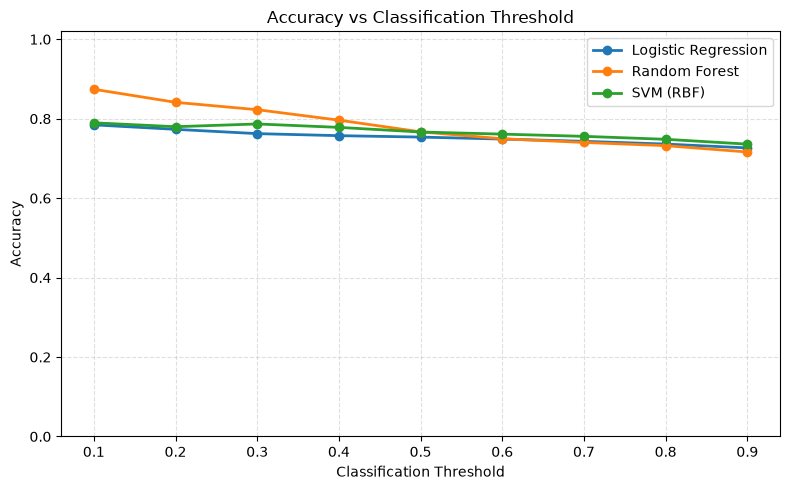

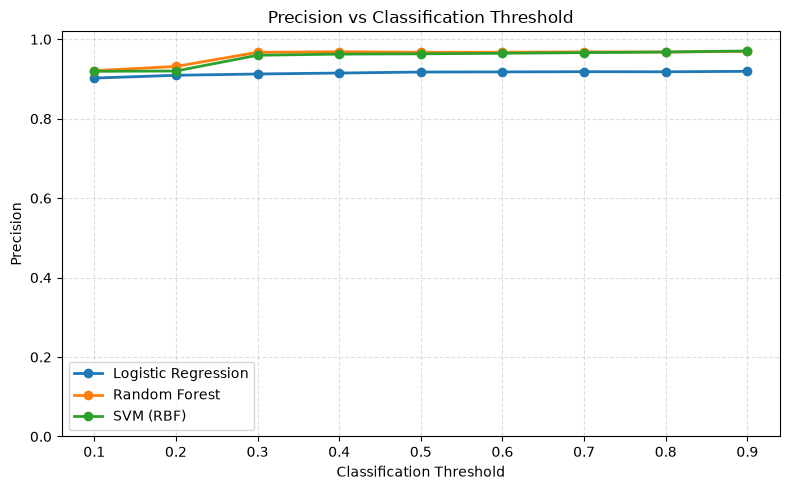

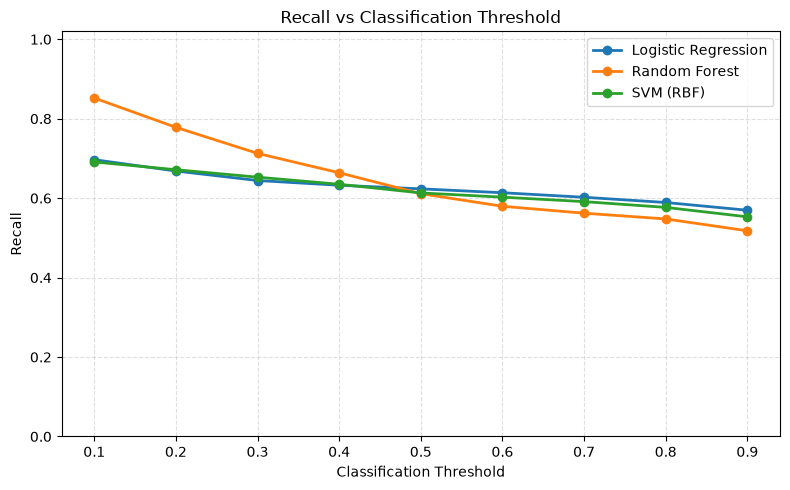

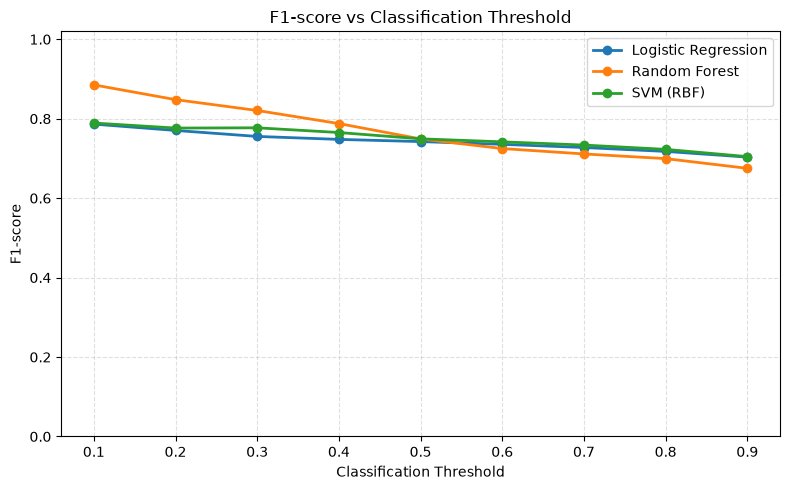

All figures saved in: /home/lkg/ml/nsl_kdd_figures


In [16]:
import matplotlib.pyplot as plt
from pathlib import Path

# Folder for saved figures
figure_dir = Path("nsl_kdd_figures")
figure_dir.mkdir(exist_ok=True)

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

for metric in metrics:
    fig, ax = plt.subplots(figsize=(8, 5))

    for model_name, group in threshold_results_df.groupby("Model"):
        group = group.sort_values("Threshold")

        ax.plot(
            group["Threshold"],
            group[metric],
            marker="o",
            linewidth=2,
            label=model_name
        )

    ax.set_xlabel("Classification Threshold")
    ax.set_ylabel(metric)
    ax.set_title(f"{metric} vs Classification Threshold")
    ax.set_xticks(sorted(threshold_results_df["Threshold"].unique()))
    ax.set_ylim(0, 1.02)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend()

    fig.tight_layout()

    filename = f"{metric.lower().replace('-', '_')}_vs_threshold.png"
    fig.savefig(
        figure_dir / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print(f"All figures saved in: {figure_dir.resolve()}")

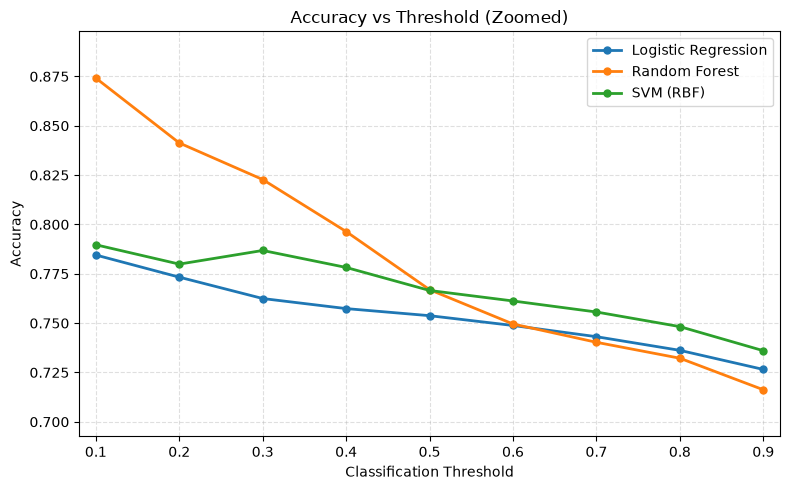

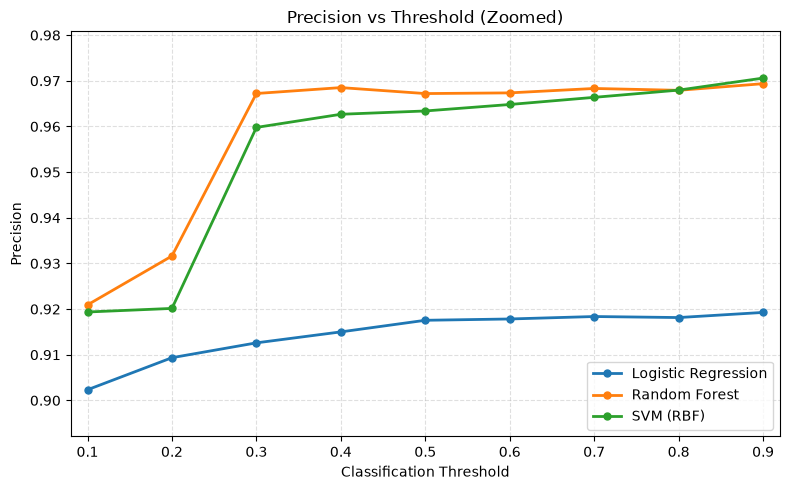

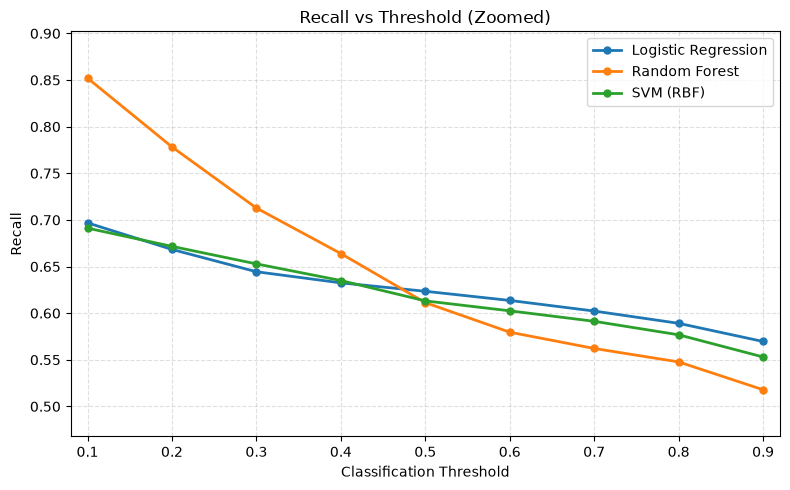

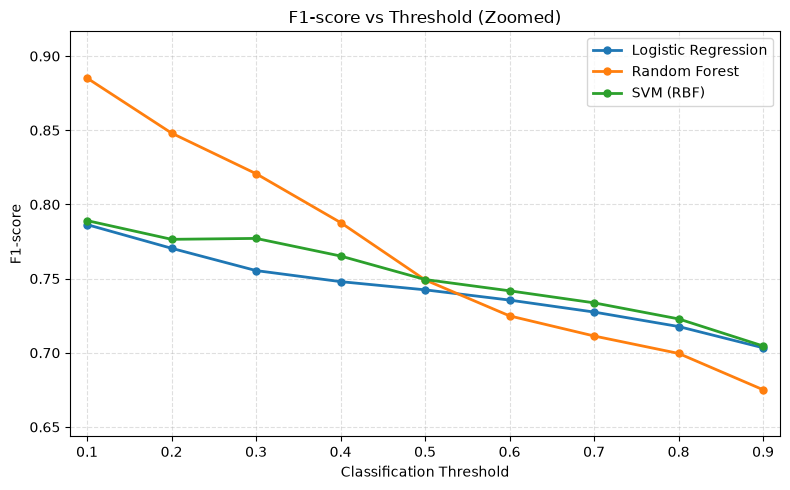

Zoomed figures saved in: /home/lkg/ml/nsl_kdd_figures


In [17]:
# Save zoomed-in figures
import matplotlib.pyplot as plt
from pathlib import Path

figure_dir = Path("nsl_kdd_figures")
figure_dir.mkdir(exist_ok=True)

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

for metric in metrics:
    fig, ax = plt.subplots(figsize=(8, 5))

    for model_name, group in threshold_results_df.groupby("Model"):
        group = group.sort_values("Threshold")

        ax.plot(
            group["Threshold"],
            group[metric],
            marker="o",
            markersize=5,
            linewidth=2,
            label=model_name
        )

    # Zoom the y-axis around the observed metric range
    metric_min = threshold_results_df[metric].min()
    metric_max = threshold_results_df[metric].max()
    margin = max((metric_max - metric_min) * 0.15, 0.005)

    lower = max(0, metric_min - margin)
    upper = min(1, metric_max + margin)

    ax.set_ylim(lower, upper)
    ax.set_xlim(0.08, 0.92)
    ax.set_xticks(sorted(threshold_results_df["Threshold"].unique()))

    ax.set_xlabel("Classification Threshold")
    ax.set_ylabel(metric)
    ax.set_title(f"{metric} vs Threshold (Zoomed)")
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend()

    fig.tight_layout()

    filename = f"{metric.lower().replace('-', '_')}_vs_threshold_zoomed.png"
    fig.savefig(
        figure_dir / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print("Zoomed figures saved in:", figure_dir.resolve())

In [18]:
# Validation
#Create the training/validation split
from sklearn.model_selection import train_test_split

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training subset:", X_train_sub.shape)
print("Validation subset:", X_val.shape)

print("\nTraining class proportions:")
print(y_train_sub.value_counts(normalize=True).sort_index().round(4))

print("\nValidation class proportions:")
print(y_val.value_counts(normalize=True).sort_index().round(4))

Training subset: (100778, 41)
Validation subset: (25195, 41)

Training class proportions:
binary_label
0   0.535
1   0.465
Name: proportion, dtype: float64

Validation class proportions:
binary_label
0   0.535
1   0.465
Name: proportion, dtype: float64


In [19]:
#Refit preprocessing using training data only
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify feature types from the training subset
categorical_features = X_train_sub.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X_train_sub.select_dtypes(
    exclude=["object"]
).columns.tolist()

# Build preprocessing pipeline
preprocessor_val = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

# Fit only on the training subset
X_train_sub_processed = preprocessor_val.fit_transform(X_train_sub)

# Transform validation data using the fitted training preprocessing
X_val_processed = preprocessor_val.transform(X_val)

print("Processed training subset:", X_train_sub_processed.shape)
print("Processed validation set:", X_val_processed.shape)

Processed training subset: (100778, 121)
Processed validation set: (25195, 121)


In [20]:
#Train all three models on the training subset
import time
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

validation_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "SVM (RBF)": SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

validation_probabilities = {}
model_training_times = {}

for name, model in validation_models.items():
    print(f"Training {name}...")

    start_time = time.perf_counter()
    model.fit(X_train_sub_processed, y_train_sub)
    model_training_times[name] = time.perf_counter() - start_time

    # Probability of Attack (class 1) on validation data
    validation_probabilities[name] = model.predict_proba(
        X_val_processed
    )[:, 1]

    print(
        f"Completed in {model_training_times[name]:.2f} seconds"
    )

print("\nValidation probability arrays:")
for name, probabilities in validation_probabilities.items():
    print(name, probabilities.shape)

Training Logistic Regression...
Completed in 11.84 seconds
Training SVM (RBF)...
Completed in 580.84 seconds
Training Random Forest...
Completed in 12.76 seconds

Validation probability arrays:
Logistic Regression (25195,)
SVM (RBF) (25195,)
Random Forest (25195,)


In [21]:
#Select the threshold using validation data
#Find the best validation threshold
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds_to_test = [
    0.1, 0.2, 0.3, 0.4, 0.5,
    0.6, 0.7, 0.8, 0.9
]

best_thresholds = {}
validation_threshold_results = []

for model_name, probabilities in validation_probabilities.items():

    best_f1 = -1
    best_threshold = None
    best_metrics = None

    for threshold in thresholds_to_test:
        predictions = (probabilities >= threshold).astype(int)

        precision = precision_score(
            y_val, predictions, zero_division=0
        )
        recall = recall_score(
            y_val, predictions, zero_division=0
        )
        f1 = f1_score(
            y_val, predictions, zero_division=0
        )

        validation_threshold_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision,
            "Recall": recall,
            "F1-score": f1
        })

        if f1 > best_f1:
            best_f1 = f1
            best_threshold = threshold
            best_metrics = (precision, recall, f1)

    best_thresholds[model_name] = best_threshold

    print(f"\n{model_name}")
    print(f"Selected threshold: {best_threshold:.1f}")
    print(f"Validation precision: {best_metrics[0]:.4f}")
    print(f"Validation recall:    {best_metrics[1]:.4f}")
    print(f"Validation F1-score:  {best_metrics[2]:.4f}")

validation_threshold_df = pd.DataFrame(
    validation_threshold_results
)

print("\nSelected thresholds:")
print(best_thresholds)


Logistic Regression
Selected threshold: 0.3
Validation precision: 0.9643
Validation recall:    0.9806
Validation F1-score:  0.9724

SVM (RBF)
Selected threshold: 0.8
Validation precision: 0.9959
Validation recall:    0.9900
Validation F1-score:  0.9929

Random Forest
Selected threshold: 0.4
Validation precision: 0.9991
Validation recall:    0.9991
Validation F1-score:  0.9991

Selected thresholds:
{'Logistic Regression': 0.3, 'SVM (RBF)': 0.8, 'Random Forest': 0.4}


In [22]:
#Final evaluation on the official test set
#Prepare the official test features
# Transform official test data using the training-subset-fitted preprocessor
X_test_final_processed = preprocessor_val.transform(X_test)

print("Official test set shape:", X_test_final_processed.shape)
print("Official test labels:", y_test.shape)

Official test set shape: (22544, 121)
Official test labels: (22544,)


In [23]:
#Evaluate all three models on the official test set
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

final_test_results = []
final_test_predictions = {}

for model_name, model in validation_models.items():

    # Predict attack probabilities on the official test set
    test_probabilities = model.predict_proba(
        X_test_final_processed
    )[:, 1]

    # Use the threshold selected on validation data
    threshold = best_thresholds[model_name]
    predictions = (test_probabilities >= threshold).astype(int)

    final_test_predictions[model_name] = predictions

    # Confusion matrix: [[TN, FP], [FN, TP]]
    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    final_test_results.append({
        "Model": model_name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

final_test_results_df = pd.DataFrame(
    final_test_results
).set_index("Model")

display(final_test_results_df.round(4))

,Threshold,Accuracy,Precision,Recall,F1-score,TN,FP,FN,TP
Model,,,,,,,,,
Logistic Regression,0.300,0.762,0.913,0.644,0.755,8920,791,4566,8267
SVM (RBF),0.800,0.751,0.969,0.581,0.727,9471,240,5372,7461
Random Forest,0.400,0.801,0.969,0.671,0.793,9437,274,4217,8616


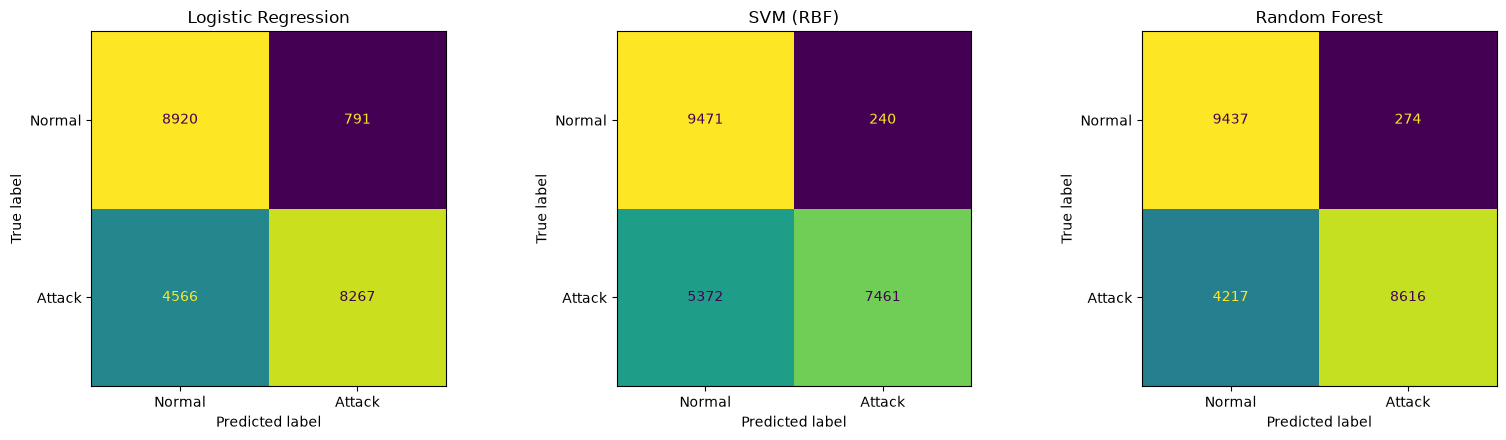

In [24]:
#Plot the confusion matrices
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (model_name, predictions) in zip(
    axes, final_test_predictions.items()
):
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Normal", "Attack"]
    )

    display.plot(
        ax=ax,
        values_format="d",
        colorbar=False
    )

    ax.set_title(model_name)

plt.tight_layout()
plt.savefig(
    "nsl_kdd_binary_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [25]:
import time

start = time.perf_counter()

lr_probabilities = validation_models[
    "Logistic Regression"
].predict_proba(X_test_final_processed)[:, 1]

lr_predictions = (
    lr_probabilities >= best_thresholds["Logistic Regression"]
).astype(int)

lr_inference_time = time.perf_counter() - start

print(f"Test samples: {len(lr_predictions)}")
print(f"Inference time: {lr_inference_time:.4f} seconds")
print(
    f"Time per sample: "
    f"{lr_inference_time / len(lr_predictions) * 1000:.6f} ms"
)

Test samples: 22544
Inference time: 0.0078 seconds
Time per sample: 0.000345 ms


In [26]:
import time

start = time.perf_counter()

svm_probabilities = validation_models[
    "SVM (RBF)"
].predict_proba(X_test_final_processed)[:, 1]

svm_predictions = (
    svm_probabilities >= best_thresholds["SVM (RBF)"]
).astype(int)

svm_inference_time = time.perf_counter() - start

print(f"Test samples: {len(svm_predictions)}")
print(f"Inference time: {svm_inference_time:.4f} seconds")
print(
    f"Time per sample: "
    f"{svm_inference_time / len(svm_predictions) * 1000:.6f} ms"
)

Test samples: 22544
Inference time: 11.7268 seconds
Time per sample: 0.520172 ms


In [27]:
import time

start = time.perf_counter()

rf_probabilities = validation_models[
    "Random Forest"
].predict_proba(X_test_final_processed)[:, 1]

rf_predictions = (
    rf_probabilities >= best_thresholds["Random Forest"]
).astype(int)

rf_inference_time = time.perf_counter() - start

print(f"Test samples: {len(rf_predictions)}")
print(f"Inference time: {rf_inference_time:.4f} seconds")
print(
    f"Time per sample: "
    f"{rf_inference_time / len(rf_predictions) * 1000:.6f} ms"
)

Test samples: 22544
Inference time: 0.1948 seconds
Time per sample: 0.008643 ms


In [28]:
import pandas as pd

inference_summary = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Test samples": 22544,
        "Inference time (s)": lr_inference_time,
        "Time per sample (ms)": lr_inference_time / 22544 * 1000
    },
    {
        "Model": "SVM (RBF)",
        "Test samples": 22544,
        "Inference time (s)": svm_inference_time,
        "Time per sample (ms)": svm_inference_time / 22544 * 1000
    },
    {
        "Model": "Random Forest",
        "Test samples": 22544,
        "Inference time (s)": rf_inference_time,
        "Time per sample (ms)": rf_inference_time / 22544 * 1000
    }
]).set_index("Model")

print(inference_summary.round(6).to_string())

                     Test samples  Inference time (s)  Time per sample (ms)
Model                                                                      
Logistic Regression         22544               0.008                 0.000
SVM (RBF)                   22544              11.727                 0.520
Random Forest               22544               0.195                 0.009


In [29]:
#Step 5.8: Create the final comparison table
# Combine final test metrics with training and inference times

final_comparison = final_test_results_df.copy()

final_comparison["Training time (s)"] = pd.Series(
    model_training_times
)

final_comparison["Inference time (s)"] = pd.Series({
    "Logistic Regression": lr_inference_time,
    "SVM (RBF)": svm_inference_time,
    "Random Forest": rf_inference_time
})

final_comparison["Inference time per sample (ms)"] = (
    final_comparison["Inference time (s)"] / len(y_test) * 1000
)

print(final_comparison.round(4).to_string())

                     Threshold  Accuracy  Precision  Recall  F1-score    TN   FP    FN    TP  Training time (s)  Inference time (s)  Inference time per sample (ms)
Model                                                                                                                                                              
Logistic Regression      0.300     0.762      0.913   0.644     0.755  8920  791  4566  8267             11.837               0.008                           0.000
SVM (RBF)                0.800     0.751      0.969   0.581     0.727  9471  240  5372  7461            580.842              11.727                           0.520
Random Forest            0.400     0.801      0.969   0.671     0.793  9437  274  4217  8616             12.759               0.195                           0.009


In [30]:
for model_name, row in final_test_results_df.iterrows():
    tn, fp, fn, tp = row["TN"], row["FP"], row["FN"], row["TP"]

    accuracy = (tn + tp) / (tn + fp + fn + tp)
    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    print(f"\n{model_name}")
    print(
        f"Accuracy: {accuracy:.4f}, "
        f"Precision: {precision:.4f}, "
        f"Recall: {recall:.4f}, "
        f"F1-score: {f1:.4f}"
    )


Logistic Regression
Accuracy: 0.7624, Precision: 0.9127, Recall: 0.6442, F1-score: 0.7553

SVM (RBF)
Accuracy: 0.7511, Precision: 0.9688, Recall: 0.5814, F1-score: 0.7267

Random Forest
Accuracy: 0.8008, Precision: 0.9692, Recall: 0.6714, F1-score: 0.7933


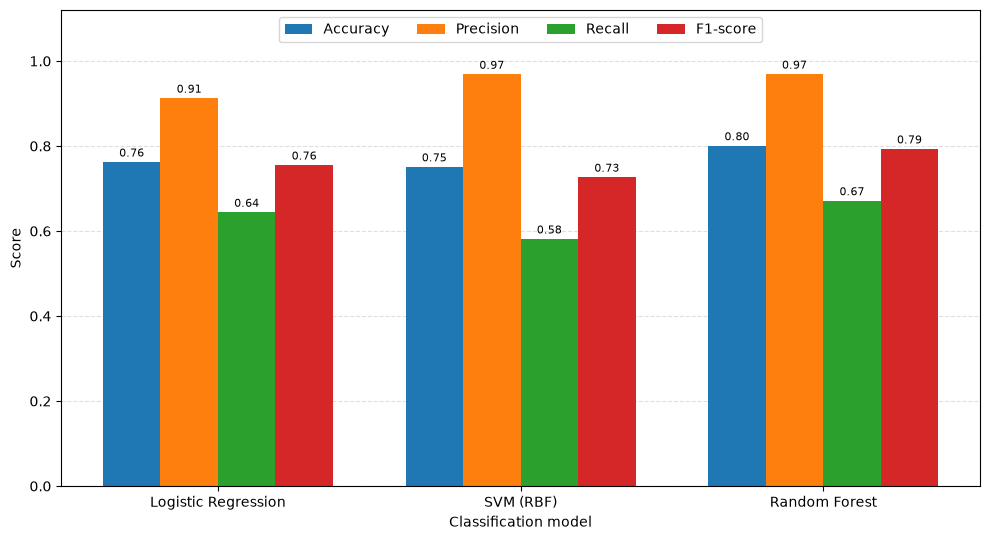

In [31]:
import numpy as np
import matplotlib.pyplot as plt

models = ["Logistic Regression", "SVM (RBF)", "Random Forest"]

metrics = {
    "Accuracy":  [0.7624, 0.7511, 0.8008],
    "Precision": [0.9127, 0.9688, 0.9692],
    "Recall":    [0.6442, 0.5814, 0.6714],
    "F1-score":  [0.7553, 0.7267, 0.7933]
}

x = np.arange(len(models))
width = 0.19

fig, ax = plt.subplots(figsize=(10, 5.5))

for i, (metric, values) in enumerate(metrics.items()):
    offset = (i - 1.5) * width
    bars = ax.bar(x + offset, values, width, label=metric)
    ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)

ax.set_xlabel("Classification model")
ax.set_ylabel("Score")
#ax.set_title("Binary Intrusion Detection: Model Performance")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 1.12)
ax.legend(ncol=4, loc="upper center")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    "nsl_kdd_binary_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()